# TanggapMakna — AI Feasibility Test (Google Colab)

**Tujuan:** memvalidasi pipeline *Semantic Role Labeling* (SRL) menggunakan **IndoBERT-Lite Base** sebelum melanjutkan ke IndoBERT Base dan pengembangan web.

### Dataset
- **Semantic Role Labeling Datasets for Crisis Event**
- Mendeley Data: https://data.mendeley.com/datasets/r76v5sjyv2/2
- DOI: https://doi.org/10.17632/r76v5sjyv2.2
- Lisensi: CC BY 4.0

### Model smoke test
- `indobenchmark/indobert-lite-base-p1`

### Urutan
1. Setup GPU
2. Upload ZIP dataset
3. Ekstrak `all-labeled-data.csv`
4. Inspeksi dan cleaning
5. Konversi BIO-SRL
6. Split berdasarkan `text_id`
7. Fine-tune IndoBERT-Lite
8. Evaluasi
9. Uji inference
10. **STOP — GO/KILL review**

## 1. Setup runtime dan library

In [ ]:
!nvidia-smi

!pip install -q -U transformers datasets accelerate evaluate seqeval iterative-stratification scikit-learn pandas matplotlib

import os
import re
import json
import random
import shutil
import zipfile
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from sklearn.preprocessing import MultiLabelBinarizer
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    DataCollatorForTokenClassification,
    TrainingArguments,
    Trainer,
    set_seed,
)
from seqeval.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    classification_report,
)

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

print("=" * 70)
print("TANGGAPMAKNA — AI FEASIBILITY TEST")
print("=" * 70)
print("PyTorch        :", torch.__version__)
print("CUDA available :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU            :", torch.cuda.get_device_name(0))
else:
    raise RuntimeError(
        "GPU belum aktif. Buka Runtime > Change runtime type > pilih GPU."
    )

Tue Aug 11 14:45:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Upload dataset ZIP

Upload file **`Semantic Role Labeling Datasets for Crisis Event.zip`**.

Notebook hanya memakai versi Bahasa Indonesia, bukan folder *English Translation*.

In [ ]:
from google.colab import files

uploaded = files.upload()

zip_candidates = [
    Path("/content") / name
    for name in uploaded.keys()
    if name.lower().endswith(".zip")
]

if not zip_candidates:
    raise RuntimeError("Tidak ditemukan file ZIP.")

ZIP_PATH = zip_candidates[0]

print("ZIP terpilih :", ZIP_PATH)
print("Ukuran ZIP   :", f"{ZIP_PATH.stat().st_size / (1024**2):.2f} MB")

Saving Semantic Role Labeling Datasets for Crisis Event.zip to Semantic Role Labeling Datasets for Crisis Event.zip
ZIP terpilih : /content/Semantic Role Labeling Datasets for Crisis Event.zip
Ukuran ZIP   : 66.71 MB


## 3. Ekstrak labeled CSV utama

In [ ]:
WORK_DIR = Path("/content/tanggapmakna")
WORK_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    names = z.namelist()

    candidates = [
        n for n in names
        if n.endswith("3-Labeled Data/all-labeled-data.csv")
        and "Version 2.0" not in n
    ]

    print("Candidate CSV:", candidates)

    if len(candidates) != 1:
        raise RuntimeError(
            f"Harus ditemukan tepat 1 CSV Indonesia utama, ditemukan {len(candidates)}."
        )

    MEMBER = candidates[0]
    z.extract(MEMBER, WORK_DIR)

CSV_PATH = WORK_DIR / MEMBER

print("CSV:", CSV_PATH)
print("Ukuran:", f"{CSV_PATH.stat().st_size / (1024**2):.2f} MB")

Candidate CSV: ['Semantic Role Labeling Datasets for Crisis Event/Semantic-Role-Labeling-Datasets-for-Crisis-Event/3-Labeled Data/all-labeled-data.csv']
CSV: /content/tanggapmakna/Semantic Role Labeling Datasets for Crisis Event/Semantic-Role-Labeling-Datasets-for-Crisis-Event/3-Labeled Data/all-labeled-data.csv
Ukuran: 3.66 MB


## 4. Inspeksi dataset

In [ ]:
df = pd.read_csv(CSV_PATH)

print("Shape          :", df.shape)
print("Columns        :", list(df.columns))
print("Unique text_id :", df["text_id"].nunique())
print("Blank token    :", df["token"].isna().sum())

display(df.head(20))

EXPECTED_COLUMNS = {"text_id", "id", "token", "entity", "argument"}
missing = EXPECTED_COLUMNS - set(df.columns)
if missing:
    raise RuntimeError(f"Kolom wajib tidak ditemukan: {missing}")

text_ids = pd.Series(df["text_id"].drop_duplicates())

print("\nDistribusi prefix berdasarkan jumlah TEKS:")
display(
    text_ids.str[:3]
    .value_counts()
    .rename_axis("prefix")
    .to_frame("jumlah_teks")
)

lengths = df.groupby("text_id").size()
print("\nStatistik panjang teks:")
display(lengths.describe().to_frame("jumlah_token"))

print("\nDistribusi argument:")
display(df["argument"].value_counts().to_frame("jumlah_token"))

Shape          : (99206, 5)
Columns        : ['text_id', 'id', 'token', 'entity', 'argument']
Unique text_id : 4150
Blank token    : 4


,text_id,id,token,entity,argument
0,BAN-00001,BAN-00001.001,13,O,O
1,BAN-00001,BAN-00001.002,janji,O,O
2,BAN-00001,BAN-00001.003,akan,O,O
3,BAN-00001,BAN-00001.004,mencari,O,O
4,BAN-00001,BAN-00001.005,solusi,O,O
5,BAN-00001,BAN-00001.006,banjir,B-EVE,FALSE-EVENT
6,BAN-00001,BAN-00001.007,jakarta,B-LOC,PLACE-ARG
7,BAN-00001,BAN-00001.008,dan,O,O
8,BAN-00001,BAN-00001.009,kemacetan,O,O
9,BAN-00001,BAN-00001.010,jakarta,B-LOC,PLACE-ARG



Distribusi prefix berdasarkan jumlah TEKS:


,jumlah_teks
prefix,
BAN,1250
KEB,1128
GEM,906
KEC,866



Statistik panjang teks:


,jumlah_token
count,4150.000000
mean,23.905060
std,12.244817
min,4.000000
25%,13.000000
50%,22.000000
75%,34.000000
max,126.000000



Distribusi argument:


,jumlah_token
argument,
O,68753
PLACE-ARG,10229
FALSE-EVENT,3448
STREET-ARG,3154
AFFECTEDOBJECTS-ARG,2789
TIME-ARG,2424
OFFICER-ARG,2113
INFORMATION-ARG,1977
FIRE-EVENT,834


### Expected sanity check

Dari file yang sudah diperiksa:
- 99.206 baris token
- 4.150 `text_id`
- 4 token kosong
- BAN 1.250 teks
- KEB 1.128 teks
- GEM 906 teks
- KEC 866 teks

Jika hasil jauh berbeda, **STOP**.

## 5. Cleaning minimal

In [ ]:
before_rows = len(df)
blank_rows = df[df["token"].isna()].copy()

print("Baris token kosong:")
display(blank_rows)

df_clean = df[df["token"].notna()].copy().reset_index(drop=True)

print("Rows before :", before_rows)
print("Rows after  :", len(df_clean))
print("Removed     :", before_rows - len(df_clean))

assert df_clean["text_id"].nunique() == 4150

Baris token kosong:


,text_id,id,token,entity,argument
19876,BAN-01841,BAN-01841.044,NaN,O,O
32070,GEM-01339,GEM-01339.018,NaN,O,O
46747,KEB-00243,KEB-00243.003,NaN,B-LOC,PLACE-ARG
47364,KEB-00266,KEB-00266.013,NaN,I-LOC,PLACE-ARG


Rows before : 99206
Rows after  : 99202
Removed     : 4


## 6. Konversi ke BIO-SRL

Kita mempertahankan batas span dari kolom `entity`, tetapi label semantiknya berasal dari `argument`.

Contoh:
- `entity = B-LOC`, `argument = PLACE-ARG` → `B-PLACE-ARG`
- `entity = I-LOC`, `argument = PLACE-ARG` → `I-PLACE-ARG`

In [ ]:
def build_bio_srl_for_group(group):
    labels = []
    prev_argument = "O"

    for _, row in group.iterrows():
        argument = str(row["argument"])
        entity = str(row["entity"])

        if argument == "O":
            bio = "O"
        elif entity.startswith("B-"):
            bio = f"B-{argument}"
        elif entity.startswith("I-"):
            bio = f"I-{argument}"
        else:
            prefix = "I" if prev_argument == argument else "B"
            bio = f"{prefix}-{argument}"

        labels.append(bio)
        prev_argument = argument

    return labels


bio_parts = []

for _, group in df_clean.groupby("text_id", sort=False):
    bio_parts.extend(build_bio_srl_for_group(group))

df_clean["bio_srl"] = bio_parts

print("Jumlah label BIO-SRL:", df_clean["bio_srl"].nunique())

display(
    df_clean["bio_srl"]
    .value_counts()
    .sort_index()
    .to_frame("jumlah_token")
)

if df_clean["bio_srl"].nunique() != 29:
    print("WARNING: jumlah label bukan 29. Periksa sebelum training.")

Jumlah label BIO-SRL: 29


,jumlah_token
bio_srl,
B-ACCIDENT-EVENT,619
B-AFFECTEDOBJECTS-ARG,1398
B-DEATHVICTIM-ARG,232
B-EARTHQUAKE-EVENT,314
B-FALSE-EVENT,2595
B-FIRE-EVENT,809
B-FLOOD-EVENT,412
B-INFORMATION-ARG,583
B-OFFICER-ARG,1340


## 7. Bentuk satu record per `text_id`

In [ ]:
records = []

for text_id, group in df_clean.groupby("text_id", sort=False):
    tokens = group["token"].astype(str).tolist()
    labels = group["bio_srl"].astype(str).tolist()

    assert len(tokens) == len(labels)

    records.append({
        "text_id": text_id,
        "tokens": tokens,
        "labels": labels,
    })

records_df = pd.DataFrame(records)

print("Jumlah laporan :", len(records_df))
print("Min token      :", records_df["tokens"].map(len).min())
print("Max token      :", records_df["tokens"].map(len).max())
print("Mean token     :", records_df["tokens"].map(len).mean())

display(records_df.head())

assert len(records_df) == 4150

Jumlah laporan : 4150
Min token      : 4
Max token      : 126
Mean token     : 23.904096385542168


,text_id,tokens,labels
0,BAN-00001,"[13, janji, akan, mencari, solusi, banjir, jak...","[O, O, O, O, O, B-FALSE-EVENT, B-PLACE-ARG, O,..."
1,BAN-00002,"[ingin, tenangkan, diri, di, musim, banjir, ?,...","[O, O, O, O, O, B-FALSE-EVENT, O, O, O, O, O, ..."
2,BAN-00003,"[intensitas, dan, curah, hujan, yang, tinggi, ...","[B-REASON-ARG, I-REASON-ARG, I-REASON-ARG, I-R..."
3,BAN-00004,"[ayuh, kita, bersama, menjayakan, misi, bantua...","[O, O, O, O, O, O, O, B-FALSE-EVENT, O, B-PLAC..."
4,BAN-00005,"[anak, buah, bantu, set, up, pusat, pemindahan...","[O, O, O, O, O, O, O, B-FALSE-EVENT, O, O, O, ..."


## 8. Multilabel-stratified split 70/15/15

Split dilakukan pada **laporan (`text_id`)**, bukan token. Ini mencegah data leakage.

In [ ]:
def base_role(bio_label):
    if bio_label == "O":
        return None
    return bio_label[2:]


records_df["role_set"] = records_df["labels"].apply(
    lambda labs: sorted({
        base_role(x)
        for x in labs
        if base_role(x) is not None
    })
)

mlb = MultiLabelBinarizer()
Y = mlb.fit_transform(records_df["role_set"])
X = np.arange(len(records_df)).reshape(-1, 1)

split1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=SEED,
)
train_idx, temp_idx = next(split1.split(X, Y))

split2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=SEED,
)
val_rel, test_rel = next(
    split2.split(X[temp_idx], Y[temp_idx])
)

val_idx = temp_idx[val_rel]
test_idx = temp_idx[test_rel]

split_indices = {
    "train": train_idx,
    "validation": val_idx,
    "test": test_idx,
}

for name, idx in split_indices.items():
    print(f"{name:<10}: {len(idx):4d} ({len(idx)/len(records_df):.2%})")

train_ids = set(records_df.iloc[train_idx]["text_id"])
val_ids = set(records_df.iloc[val_idx]["text_id"])
test_ids = set(records_df.iloc[test_idx]["text_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("\n✅ Tidak ada text_id yang bocor antar split.")

train     : 2905 (70.00%)
validation:  622 (14.99%)
test      :  623 (15.01%)

✅ Tidak ada text_id yang bocor antar split.


## 9. Cek distribusi role setiap split

In [ ]:
def role_presence_counts(sub_df):
    counter = Counter()
    for roles in sub_df["role_set"]:
        counter.update(set(roles))
    return counter


summary_rows = []

for split_name, idx in split_indices.items():
    sub = records_df.iloc[idx]
    counts = role_presence_counts(sub)

    for role in sorted(mlb.classes_):
        summary_rows.append({
            "split": split_name,
            "role": role,
            "texts_with_role": counts.get(role, 0),
        })

split_role_summary = pd.DataFrame(summary_rows)

pivot = split_role_summary.pivot(
    index="role",
    columns="split",
    values="texts_with_role",
).fillna(0).astype(int)

display(pivot)

rare_test = pivot[pivot["test"] == 0]

if len(rare_test):
    print("WARNING: role berikut tidak muncul pada test:")
    display(rare_test)
else:
    print("✅ Semua role dasar muncul pada test.")

split,test,train,validation
role,,,
ACCIDENT-EVENT,88,407,87
AFFECTEDOBJECTS-ARG,169,790,169
DEATHVICTIM-ARG,32,150,32
EARTHQUAKE-EVENT,37,171,36
FALSE-EVENT,342,1597,342
FIRE-EVENT,98,458,98
FLOOD-EVENT,56,260,55
INFORMATION-ARG,74,343,73
OFFICER-ARG,146,683,146


✅ Semua role dasar muncul pada test.


## 10. Label map dan Hugging Face Dataset

In [ ]:
label_list = ["O"] + sorted(
    x for x in df_clean["bio_srl"].unique()
    if x != "O"
)

label2id = {label: i for i, label in enumerate(label_list)}
id2label = {i: label for label, i in label2id.items()}

print("Jumlah label:", len(label_list))
print(json.dumps(label2id, indent=2, ensure_ascii=False))


def make_hf_dataset(indices):
    sub = records_df.iloc[indices].reset_index(drop=True)

    return Dataset.from_dict({
        "text_id": sub["text_id"].tolist(),
        "tokens": sub["tokens"].tolist(),
        "labels_str": sub["labels"].tolist(),
    })


train_ds = make_hf_dataset(train_idx)
val_ds = make_hf_dataset(val_idx)
test_ds = make_hf_dataset(test_idx)

print(train_ds)
print(val_ds)
print(test_ds)

Jumlah label: 29
{
  "O": 0,
  "B-ACCIDENT-EVENT": 1,
  "B-AFFECTEDOBJECTS-ARG": 2,
  "B-DEATHVICTIM-ARG": 3,
  "B-EARTHQUAKE-EVENT": 4,
  "B-FALSE-EVENT": 5,
  "B-FIRE-EVENT": 6,
  "B-FLOOD-EVENT": 7,
  "B-INFORMATION-ARG": 8,
  "B-OFFICER-ARG": 9,
  "B-PLACE-ARG": 10,
  "B-REASON-ARG": 11,
  "B-STREET-ARG": 12,
  "B-TIME-ARG": 13,
  "B-WOUNDVICTIM-ARG": 14,
  "I-ACCIDENT-EVENT": 15,
  "I-AFFECTEDOBJECTS-ARG": 16,
  "I-DEATHVICTIM-ARG": 17,
  "I-EARTHQUAKE-EVENT": 18,
  "I-FALSE-EVENT": 19,
  "I-FIRE-EVENT": 20,
  "I-FLOOD-EVENT": 21,
  "I-INFORMATION-ARG": 22,
  "I-OFFICER-ARG": 23,
  "I-PLACE-ARG": 24,
  "I-REASON-ARG": 25,
  "I-STREET-ARG": 26,
  "I-TIME-ARG": 27,
  "I-WOUNDVICTIM-ARG": 28
}
Dataset({
    features: ['text_id', 'tokens', 'labels_str'],
    num_rows: 2905
})
Dataset({
    features: ['text_id', 'tokens', 'labels_str'],
    num_rows: 622
})
Dataset({
    features: ['text_id', 'tokens', 'labels_str'],
    num_rows: 623
})


## 11. Load IndoBERT-Lite + alignment subword

Model smoke:
`indobenchmark/indobert-lite-base-p1`

Kita memberi label hanya pada **subword pertama** dari setiap token asli. Subword lain diberi `-100` agar tidak ikut dihitung oleh loss.

In [ ]:
MODEL_NAME = "indobenchmark/indobert-lite-base-p1"
MAX_LENGTH = 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer class :", tokenizer.__class__.__name__)
print("Fast tokenizer  :", getattr(tokenizer, "is_fast", False))
print("Vocab size      :", len(tokenizer))


def encode_words_and_labels(example):
    input_ids = [tokenizer.cls_token_id]
    label_ids = [-100]

    for word, label in zip(example["tokens"], example["labels_str"]):
        pieces = tokenizer.tokenize(str(word))

        if not pieces:
            pieces = [tokenizer.unk_token]

        piece_ids = tokenizer.convert_tokens_to_ids(pieces)

        remaining = MAX_LENGTH - 1 - len(input_ids)

        if remaining <= 0:
            break

        piece_ids = piece_ids[:remaining]

        input_ids.extend(piece_ids)

        label_ids.append(label2id[label])
        label_ids.extend([-100] * (len(piece_ids) - 1))

    input_ids.append(tokenizer.sep_token_id)
    label_ids.append(-100)

    attention_mask = [1] * len(input_ids)

    assert len(input_ids) == len(label_ids) == len(attention_mask)

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": label_ids,
    }


train_encoded = train_ds.map(
    encode_words_and_labels,
    remove_columns=train_ds.column_names,
)

val_encoded = val_ds.map(
    encode_words_and_labels,
    remove_columns=val_ds.column_names,
)

test_encoded = test_ds.map(
    encode_words_and_labels,
    remove_columns=test_ds.column_names,
)

print(train_encoded[0])
print("Encoded length:", len(train_encoded[0]["input_ids"]))

config.json:   0%|          | 0.00/1.54k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Tokenizer class : AlbertTokenizer
Fast tokenizer  : True
Vocab size      : 5


Map:   0%|          | 0/2905 [00:00<?, ? examples/s]

Map:   0%|          | 0/622 [00:00<?, ? examples/s]

Map:   0%|          | 0/623 [00:00<?, ? examples/s]

{'input_ids': [2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'labels': [-100, 0, 0, 0, 0, 0, 5, 10, 0, 0, 10, 0, 0, 9, 0, 0, 0, 13, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 10, 0, 5, 0, 0, 0, 0, 0, -100]}
Encoded length: 43


## 12. Cek truncation sebelum training

,wordpiece_length
count,4150.000000
mean,25.904096
std,12.244377
min,6.000000
25%,15.000000
50%,24.000000
75%,36.000000
max,128.000000


Jumlah laporan > MAX_LENGTH: 0 / 4150


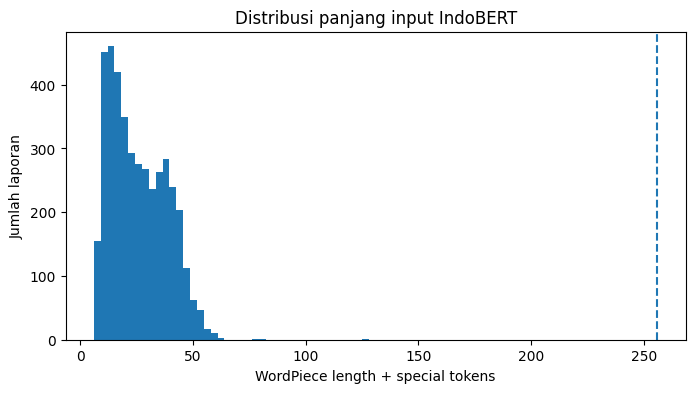

In [ ]:
def encoded_length(tokens):
    total = 2  # CLS + SEP

    for word in tokens:
        pieces = tokenizer.tokenize(str(word))
        total += max(1, len(pieces))

    return total


encoded_lengths = records_df["tokens"].apply(encoded_length)

display(encoded_lengths.describe().to_frame("wordpiece_length"))

too_long = int((encoded_lengths > MAX_LENGTH).sum())

print(
    "Jumlah laporan > MAX_LENGTH:",
    too_long,
    "/",
    len(encoded_lengths),
)

plt.figure(figsize=(8, 4))
plt.hist(encoded_lengths, bins=40)
plt.axvline(MAX_LENGTH, linestyle="--")
plt.xlabel("WordPiece length + special tokens")
plt.ylabel("Jumlah laporan")
plt.title("Distribusi panjang input IndoBERT")
plt.show()

## 13. Model token classification dan metrik

In [ ]:
model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_list),
    id2label=id2label,
    label2id=label2id,
)

data_collator = DataCollatorForTokenClassification(
    tokenizer=tokenizer,
    label_pad_token_id=-100,
)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    true_predictions = []
    true_labels = []

    for pred_row, label_row in zip(predictions, labels):
        pred_tags = []
        gold_tags = []

        for pred_id, gold_id in zip(pred_row, label_row):
            if gold_id == -100:
                continue

            pred_tags.append(id2label[int(pred_id)])
            gold_tags.append(id2label[int(gold_id)])

        true_predictions.append(pred_tags)
        true_labels.append(gold_tags)

    return {
        "precision": precision_score(true_labels, true_predictions),
        "recall": recall_score(true_labels, true_predictions),
        "f1": f1_score(true_labels, true_predictions),
        "accuracy": accuracy_score(true_labels, true_predictions),
    }


print("Model class:", model.__class__.__name__)

[transformers] You passed `num_labels=29` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 46.7MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/23 [00:00<?, ?it/s]

[transformers] AlbertForTokenClassification LOAD REPORT from: indobenchmark/indobert-lite-base-p1
Key               | Status     | 
------------------+------------+-
pooler.weight     | UNEXPECTED | 
pooler.bias       | UNEXPECTED | 
classifier.weight | MISSING    | 
classifier.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model class: AlbertForTokenClassification


## 14. SMOKE TRAINING — 1 epoch

**Tujuan bukan skor final.** Kita hanya mengecek apakah pipeline belajar dan prediksi tidak collapse seluruhnya menjadi `O`.

In [ ]:
OUTPUT_DIR = "/content/tanggapmakna_indobert_lite_smoke"

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    learning_rate=3e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=1,
    report_to="none",
    seed=SEED,
    fp16=torch.cuda.is_available(),
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_encoded,
    eval_dataset=val_encoded,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

train_result = trainer.train()

print("\n" + "=" * 70)
print("SMOKE TRAINING SELESAI")
print("=" * 70)
print(train_result)

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.7MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,1.490306,1.428737,0.000000,0.000000,0.000000,0.696025


/usr/local/lib/python3.12/dist-packages/seqeval/metrics/v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


SMOKE TRAINING SELESAI
TrainOutput(global_step=182, training_loss=1.5044696095225576, metrics={'train_runtime': 15.7908, 'train_samples_per_second': 183.968, 'train_steps_per_second': 11.526, 'total_flos': 6016616964540.0, 'train_loss': 1.5044696095225576, 'epoch': 1.0})


## 15. Evaluasi validation dan test

In [ ]:
val_metrics = trainer.evaluate(
    val_encoded,
    metric_key_prefix="val",
)

test_metrics = trainer.evaluate(
    test_encoded,
    metric_key_prefix="test",
)

print("VALIDATION")
print(json.dumps(val_metrics, indent=2))

print("\nTEST")
print(json.dumps(test_metrics, indent=2))

/usr/local/lib/python3.12/dist-packages/seqeval/metrics/v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Accuracy
1.490306,1.428737,1,0.000000,0.000000,0.000000,0.696025


Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Accuracy
1.490306,1.460867,1,0.000000,0.000000,0.000000,0.689689


VALIDATION
{
  "val_loss": 1.428736686706543,
  "val_precision": 0.0,
  "val_recall": 0.0,
  "val_f1": 0.0,
  "val_accuracy": 0.69602462856378
}

TEST
{
  "test_loss": 1.4608674049377441,
  "test_precision": 0.0,
  "test_recall": 0.0,
  "test_f1": 0.0,
  "test_accuracy": 0.68968877915665
}


## 16. Classification report per role

In [ ]:
pred_output = trainer.predict(test_encoded)

pred_ids = np.argmax(
    pred_output.predictions,
    axis=-1,
)

gold_ids = pred_output.label_ids

all_pred_tags = []
all_gold_tags = []

for pred_row, gold_row in zip(pred_ids, gold_ids):
    pred_tags = []
    gold_tags = []

    for pred_id, gold_id in zip(pred_row, gold_row):
        if gold_id == -100:
            continue

        pred_tags.append(id2label[int(pred_id)])
        gold_tags.append(id2label[int(gold_id)])

    all_pred_tags.append(pred_tags)
    all_gold_tags.append(gold_tags)

report_text = classification_report(
    all_gold_tags,
    all_pred_tags,
    digits=4,
    zero_division=0,
)

print(report_text)

                     precision    recall  f1-score   support

     ACCIDENT-EVENT     0.0000    0.0000    0.0000        93
AFFECTEDOBJECTS-ARG     0.0000    0.0000    0.0000       204
    DEATHVICTIM-ARG     0.0000    0.0000    0.0000        34
   EARTHQUAKE-EVENT     0.0000    0.0000    0.0000        53
        FALSE-EVENT     0.0000    0.0000    0.0000       397
         FIRE-EVENT     0.0000    0.0000    0.0000       123
        FLOOD-EVENT     0.0000    0.0000    0.0000        62
    INFORMATION-ARG     0.0000    0.0000    0.0000        99
        OFFICER-ARG     0.0000    0.0000    0.0000       212
          PLACE-ARG     0.0000    0.0000    0.0000      1048
         REASON-ARG     0.0000    0.0000    0.0000        34
         STREET-ARG     0.0000    0.0000    0.0000       135
           TIME-ARG     0.0000    0.0000    0.0000       213
    WOUNDVICTIM-ARG     0.0000    0.0000    0.0000        19

          micro avg     0.0000    0.0000    0.0000      2726
          macro avg   

## 17. Error analysis

In [ ]:
def predict_token_labels(tokens):
    example = {
        "tokens": tokens,
        "labels_str": ["O"] * len(tokens),
    }

    encoded = encode_words_and_labels(example)

    model_inputs = {
        "input_ids": torch.tensor(
            [encoded["input_ids"]]
        ).to(model.device),
        "attention_mask": torch.tensor(
            [encoded["attention_mask"]]
        ).to(model.device),
    }

    with torch.no_grad():
        logits = model(**model_inputs).logits[0]

    pred = logits.argmax(dim=-1).cpu().tolist()

    result = []
    cursor = 1  # setelah CLS

    for word in tokens:
        pieces = tokenizer.tokenize(str(word))

        if not pieces:
            pieces = [tokenizer.unk_token]

        if cursor >= len(pred) - 1:
            break

        result.append(id2label[int(pred[cursor])])
        cursor += len(pieces)

    return result


sample_test = records_df.iloc[test_idx].sample(
    min(10, len(test_idx)),
    random_state=SEED,
)

for _, row in sample_test.iterrows():
    tokens = row["tokens"]
    gold = row["labels"]
    pred = predict_token_labels(tokens)

    n = min(len(tokens), len(pred), len(gold))

    print("\n" + "=" * 90)
    print("TEXT ID:", row["text_id"])
    print("TEXT   :", " ".join(tokens))

    rows = []

    for i in range(n):
        if gold[i] != "O" or pred[i] != "O":
            rows.append({
                "token": tokens[i],
                "gold": gold[i],
                "pred": pred[i],
                "benar": gold[i] == pred[i],
            })

    display(pd.DataFrame(rows))


TEXT ID: GEM-01633
TEXT   : berbagai kasus ini memberikan gambaran bahwa tsunami yang tidak didahului oleh gempa bumi sudah berkali-kali terjadi di indonesia


,token,gold,pred,benar
0,gempa,B-FALSE-EVENT,O,False
1,bumi,I-FALSE-EVENT,O,False
2,indonesia,B-PLACE-ARG,O,False



TEXT ID: GEM-01073
TEXT   : mungkin ini bisa menjadi salah satu rujukan dari kitab taubat ibn qudamah kalo yang gempa bumi belon pernah membaca di kitab mana


,token,gold,pred,benar
0,gempa,B-FALSE-EVENT,O,False
1,bumi,I-FALSE-EVENT,O,False



TEXT ID: GEM-00119
TEXT   : dariku dan kamu yang mungkin punya rejeki untuk memberi donasi informasi lebih lanjut klik link di bawah ini donasi gempa bumi demi pendidikan siswa sekolah di kabupaten sukabumi - via


...

,token,gold,pred,benar
0,ojk,B-OFFICER-ARG,O,False
1,gempa,B-FALSE-EVENT,O,False
2,bumi,I-FALSE-EVENT,O,False



TEXT ID: KEC-01356
TEXT   : warga gunungkidul tewas kecelakaan di jalan paris via polres


,token,gold,pred,benar
0,warga,B-DEATHVICTIM-ARG,O,False
1,gunungkidul,B-PLACE-ARG,O,False
2,kecelakaan,B-ACCIDENT-EVENT,O,False
3,jalan,B-STREET-ARG,O,False
4,paris,I-STREET-ARG,O,False
5,polres,B-OFFICER-ARG,O,False



TEXT ID: BAN-01935
TEXT   : kesigapan polri salurkan bantuan untuk korban banjir di konawe utara polri memberikan bantuan untuk korban bencana banjir bandang di wilayah konawe utara sulawesi tenggara


,token,gold,pred,benar
0,polri,B-OFFICER-ARG,O,False
1,banjir,B-FALSE-EVENT,O,False
2,konawe,B-PLACE-ARG,O,False
3,utara,I-PLACE-ARG,O,False
4,polri,B-OFFICER-ARG,O,False
5,banjir,B-FALSE-EVENT,O,False
6,bandang,I-FALSE-EVENT,O,False
7,konawe,B-PLACE-ARG,O,False
8,utara,I-PLACE-ARG,O,False
9,sulawesi,B-PLACE-ARG,O,False


## 18. Uji inference pada laporan baru

In [ ]:
def simple_word_tokenize(text):
    return re.findall(
        r"\w+(?:[-']\w+)*|[^\w\s]",
        text.lower(),
        flags=re.UNICODE,
    )


def bio_to_spans(tokens, labels):
    spans = []
    current_role = None
    current_tokens = []

    def flush():
        nonlocal current_role, current_tokens

        if current_role is not None and current_tokens:
            spans.append({
                "role": current_role,
                "text": " ".join(current_tokens),
            })

        current_role = None
        current_tokens = []

    for token, label in zip(tokens, labels):
        if label == "O":
            flush()
            continue

        prefix, role = label.split("-", 1)

        if prefix == "B" or role != current_role:
            flush()
            current_role = role
            current_tokens = [token]
        else:
            current_tokens.append(token)

    flush()
    return spans


def predict_report(text):
    tokens = simple_word_tokenize(text)
    labels = predict_token_labels(tokens)

    tokens = tokens[:len(labels)]

    spans = bio_to_spans(
        tokens,
        labels,
    )

    print("INPUT:")
    print(text)

    print("\nTOKEN + LABEL:")
    display(
        pd.DataFrame({
            "token": tokens,
            "pred": labels,
        })
    )

    print("\nEXTRACTED SPANS:")
    display(pd.DataFrame(spans))

    return {
        "tokens": tokens,
        "labels": labels,
        "spans": spans,
    }


examples = [
    "Banjir terjadi di Sukarame dan merendam beberapa rumah.",
    "Kebakaran terjadi di sebuah pasar pada malam hari.",
    "Gempa mengguncang wilayah Lampung sekitar pukul 14.30.",
    "Pemerintah sedang membahas solusi banjir Jakarta.",
]

for text in examples:
    print("\n" + "#" * 90)
    _ = predict_report(text)


##########################################################################################
INPUT:
Banjir terjadi di Sukarame dan merendam beberapa rumah.

TOKEN + LABEL:


,token,pred
0,banjir,O
1,terjadi,O
2,di,O
3,sukarame,O
4,dan,O
5,merendam,O
6,beberapa,O
7,rumah,O
8,.,O



EXTRACTED SPANS:


""



##########################################################################################
INPUT:
Kebakaran terjadi di sebuah pasar pada malam hari.

TOKEN + LABEL:


...

""



##########################################################################################
INPUT:
Pemerintah sedang membahas solusi banjir Jakarta.

TOKEN + LABEL:


,token,pred
0,pemerintah,O
1,sedang,O
2,membahas,O
3,solusi,O
4,banjir,O
5,jakarta,O
6,.,O



EXTRACTED SPANS:


""


## 19. Prototype Completeness Engine

In [ ]:
EVENT_ROLES = {
    "FLOOD-EVENT",
    "EARTHQUAKE-EVENT",
    "FIRE-EVENT",
    "ACCIDENT-EVENT",
}

LOCATION_ROLES = {
    "PLACE-ARG",
    "STREET-ARG",
}

IMPACT_ROLES = {
    "AFFECTEDOBJECTS-ARG",
    "INFORMATION-ARG",
}

TIME_ROLES = {
    "TIME-ARG",
}

VICTIM_ROLES = {
    "DEATHVICTIM-ARG",
    "WOUNDVICTIM-ARG",
}


def completeness_from_spans(spans):
    roles = {x["role"] for x in spans}

    status = {
        "event": bool(roles & EVENT_ROLES),
        "location": bool(roles & LOCATION_ROLES),
        "impact": bool(roles & IMPACT_ROLES),
        "time": bool(roles & TIME_ROLES),
        "victim": bool(roles & VICTIM_ROLES),
    }

    score = sum(status.values()) / len(status)

    missing_questions = []

    if not status["event"]:
        missing_questions.append(
            "Jenis kejadian apa yang sedang dilaporkan?"
        )

    if not status["location"]:
        missing_questions.append(
            "Di mana lokasi kejadian?"
        )

    if not status["impact"]:
        missing_questions.append(
            "Apa dampak yang terlihat atau objek apa yang terdampak?"
        )

    if not status["time"]:
        missing_questions.append(
            "Kapan kejadian atau kondisi ini diamati?"
        )

    if not status["victim"]:
        missing_questions.append(
            "Apakah terdapat korban? Jika tidak tahu, pilih 'Tidak tahu'."
        )

    return {
        "status": status,
        "completeness_score": score,
        "missing_questions": missing_questions,
    }


demo = predict_report(
    "Banjir terjadi di Sukarame dekat pasar."
)

result = completeness_from_spans(
    demo["spans"]
)

print("\nCOMPLETENESS RESULT")
print(
    json.dumps(
        result,
        indent=2,
        ensure_ascii=False,
    )
)

INPUT:
Banjir terjadi di Sukarame dekat pasar.

TOKEN + LABEL:


,token,pred
0,banjir,O
1,terjadi,O
2,di,O
3,sukarame,O
4,dekat,O
5,pasar,O
6,.,O



EXTRACTED SPANS:


""



COMPLETENESS RESULT
{
  "status": {
    "event": false,
    "location": false,
    "impact": false,
    "time": false,
    "victim": false
  },
  "completeness_score": 0.0,
  "missing_questions": [
    "Jenis kejadian apa yang sedang dilaporkan?",
    "Di mana lokasi kejadian?",
    "Apa dampak yang terlihat atau objek apa yang terdampak?",
    "Kapan kejadian atau kondisi ini diamati?",
    "Apakah terdapat korban? Jika tidak tahu, pilih 'Tidak tahu'."
  ]
}


# ⛔ CHECKPOINT — STOP DI SINI

**Jangan lanjut IndoBERT Base dulu.**

Kirim hasil berikut ke ChatGPT:

1. **Cell 4** — `Shape`, `Unique text_id`, `Blank token`, distribusi argument.
2. **Cell 9** — tabel distribusi role train/validation/test.
3. **Cell 12** — jumlah laporan yang melebihi `MAX_LENGTH=256`.
4. Output akhir **Cell 14** smoke training.
5. `val_f1` dan `test_f1` dari **Cell 15**.
6. Classification report **Cell 16**.
7. Hasil 4 contoh inference **Cell 18**.

### GO
- pipeline selesai tanpa error;
- model memprediksi label non-`O`;
- span extraction mulai masuk akal.

### Conditional GO
- pipeline benar tetapi label langka lemah;
- lanjut analisis imbalance / IndoBERT Base.

### Revise/Kill
- prediction collapse ke `O`;
- alignment label salah;
- split bocor;
- terlalu banyak data terpotong.

**1 epoch bukan eksperimen final.** Ini hanya smoke test.

## 20. Opsional — simpan artefak smoke model

In [ ]:
EXPORT_DIR = Path(
    "/content/TanggapMakna_IndoBERTLite_Smoke"
)
EXPORT_DIR.mkdir(exist_ok=True)

trainer.save_model(EXPORT_DIR)
tokenizer.save_pretrained(EXPORT_DIR)

(EXPORT_DIR / "label2id.json").write_text(
    json.dumps(
        label2id,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

(EXPORT_DIR / "id2label.json").write_text(
    json.dumps(
        id2label,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

split_manifest = {
    name: records_df.iloc[idx]["text_id"].tolist()
    for name, idx in split_indices.items()
}

(EXPORT_DIR / "split_manifest.json").write_text(
    json.dumps(
        split_manifest,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

archive = shutil.make_archive(
    "/content/TanggapMakna_IndoBERTLite_Smoke",
    "zip",
    root_dir=EXPORT_DIR,
)

print("Saved:", archive)